# Clase 8 · Muchos árboles, el mismo techo: Random Forest, XGBoost, LightGBM y CatBoost

**Machine Learning** · Programa de Especialización Data Scientist · Módulo 2 · Sesión 8 de 15

Docente: **Josef Renato Rodriguez**

---

## Dónde quedamos

En la Clase 7 probamos cuatro modelos sobre el caso del banco, cada uno con el umbral que más ganaba en validación.
La logística, el árbol de 2 niveles y el KNN quedaron a menos de €130 entre sí en el OOT de 2010
(alrededor de **€14 400**). La conclusión fue que **el umbral vale más que el modelo**.

En la Clase 4, con California Housing, juntar árboles cambió todo: XGBoost subió el R² de 0.651 (regresión lineal)
a **0.841**. Hoy hacemos la misma pregunta con el banco:

1. **¿Muchos árboles juntos le ganan por fin a la logística?** Random Forest y tres boostings: XGBoost, LightGBM y CatBoost.
2. **¿Qué tan seguros estamos de que un modelo le gana a otro?** Con 2 058 clientes en el OOT, €300 de diferencia pueden ser ruido.

Y cerramos el **Módulo 2** con la tabla completa de modelos y preguntas tipo examen.

## Qué vas a hacer hoy

| Bloque | Fase CRISP-DM | Contenido | Min |
|---|---|---|---|
| 1 | Modelar | Random Forest para clasificar: votos, hojas mínimas y el OOB | 25 |
| 2 | Evaluar | ¿Qué mira el bosque? Importancia por impureza y por permutación | 10 |
| 3 | Modelar | Tres boostings: XGBoost, LightGBM y CatBoost | 35 |
| 4 | Evaluar | La tabla del Módulo 2 y el bootstrap de la ganancia | 25 |
| 5 | | Cierre del Módulo 2: preguntas tipo examen (lo que no alcance, de tarea) | 12 |

Igual que siempre: completa las celdas **`TU CÓDIGO`** y ejecuta la **`VERIFICACIÓN`** de abajo.
El notebook completo tarda unos tres minutos en Colab. La primera vez, la Celda 0 instala CatBoost, que Colab no trae.

---
## Celda 0 · Librerías, datos y la base de la Clase 6

La celda descarga `fuentes_banco.zip` del repositorio del curso (es el mismo de la Clase 6), arma la base con la
escalera de la Clase 6, corta por tiempo y entrena **la regresión logística de la Clase 6, que sigue siendo el modelo
a batir**.

Además deja listas cuatro cosas que usamos todo el día:

- `Xe`, `Xv`, `Xo`: las variables ya codificadas (sin escalar) de entrenamiento, validación y OOT. XGBoost las necesita así para la parada temprana.
- `Se`, `Sv`, `So`: las mismas variables **sin codificar**, con las categorías como texto. CatBoost las usa así.
- `y_ent`, `y_val`, `y_oot`: la variable objetivo de cada período.
- `ganancia_campana` y `umbral_por_ganancia`: la cuenta de la Clase 7, con €25 por llamada y €60 por venta.

Si la descarga falla, sube el zip a mano con el botón de archivos de Colab y vuelve a ejecutar.

In [1]:
import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_recall_curve
try:
    from xgboost import XGBClassifier
except ImportError:                      # Colab ya lo trae; en otra máquina: pip install xgboost
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
    from xgboost import XGBClassifier
for paquete in ["lightgbm", "catboost"]:   # Colab trae lightgbm; catboost se instala la primera vez (unos 20 s)
    try:
        __import__(paquete)
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import warnings
warnings.filterwarnings("ignore")

SEED = 42
NAVY, BLUE, MAG, GREEN, GRAY = "#0A2559", "#1A56E8", "#E6115E", "#12B886", "#5B6B87"
plt.rcParams.update({
    "figure.figsize": (7, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

def check(nombre, obtenido, esperado, tol=1e-3):
    if obtenido is None:
        print(f"[ ] {nombre}: todavía no calculaste nada")
        return False
    ok = abs(float(obtenido) - float(esperado)) <= tol
    print(f"{'[OK]' if ok else '[X ]'} {nombre}")
    print(f"     tu resultado: {float(obtenido):.4f}   |   esperado: {float(esperado):.4f}")
    return ok

def check_bool(nombre, cond, pista=""):
    print(f"{'[OK]' if cond else '[X ]'} {nombre}")
    if not cond and pista:
        print(f"     pista: {pista}")
    return bool(cond)

# ── Datos: los mismos de la Clase 6 ──────────────────────────────────────────
URL = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase_6/Data/fuentes_banco.zip"
if not os.path.exists("fuentes") and not os.path.exists("fuentes_banco.zip"):
    try:
        urllib.request.urlretrieve(URL, "fuentes_banco.zip")
        print("fuentes_banco.zip descargado del repositorio del curso")
    except Exception as e:
        print(f"No se pudo descargar ({e}). Súbelo a mano al panel de archivos de Colab.")
if not os.path.exists("fuentes") and os.path.exists("fuentes_banco.zip"):
    zipfile.ZipFile("fuentes_banco.zip").extractall(".")
if not os.path.exists("fuentes"):
    raise FileNotFoundError("Falta fuentes_banco.zip: súbelo al panel de archivos de Colab y vuelve a ejecutar esta celda.")

def construir_base(ruta="fuentes"):
    """La escalera de la Clase 6, completa, en una función."""
    gestiones = pd.read_csv(f"{ruta}/gestiones.csv", dtype={"cliente_id": str})
    historial = pd.read_csv(f"{ruta}/historial_campanas.csv")
    clientes = pd.read_csv(f"{ruta}/clientes.csv")
    macro = pd.read_csv(f"{ruta}/macro_mensual.csv")
    respuestas = pd.read_csv(f"{ruta}/respuestas.csv")
    base = gestiones.copy()
    base["cliente_id"] = base["cliente_id"].astype(int)                                            # peldaño 1
    base = base.merge(historial, on=["cliente_id", "periodo"], how="left", validate="one_to_one")
    unicos = clientes.sort_values("fecha_actualizacion").drop_duplicates("cliente_id", keep="last")  # peldaño 2
    base = base.merge(unicos, on="cliente_id", how="left", validate="many_to_one")
    base["fecha_llamada"] = pd.to_datetime(base["periodo"])                                         # peldaño 3
    macro["fecha_publicacion"] = pd.to_datetime(macro["periodo"]) + pd.offsets.MonthBegin(1)
    base = pd.merge_asof(base.sort_values("fecha_llamada"),
                         macro.rename(columns={"periodo": "periodo_macro"}).sort_values("fecha_publicacion"),
                         left_on="fecha_llamada", right_on="fecha_publicacion", direction="backward")
    base = base.merge(respuestas, on=["cliente_id", "periodo"], how="left", validate="one_to_one")   # peldaño 4
    base["contactado_antes"] = (base["dias_ultimo_contacto"] != 999).astype(int)
    return base.sort_values("gestion_id").reset_index(drop=True)

datos = construir_base()

# ── El corte temporal y las variables de la Clase 6 (sin fugas, sin macro) ──────
ent = datos[datos["periodo"] <= "2009-06"]
val = datos[(datos["periodo"] >= "2009-07") & (datos["periodo"] <= "2009-12")]
oot = datos[datos["periodo"] >= "2010-01"]
NUM = ["edad", "contactos_previos", "contactado_antes"]
CAT = ["ocupacion", "estado_civil", "educacion", "mora_previa", "hipoteca", "prestamo_consumo",
       "canal", "dia_semana", "resultado_previo"]
X = NUM + CAT

def preparar(escalar=True):
    """Imputa, escala las numéricas (si escalar=True) y codifica las categóricas."""
    num = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()) if escalar else SimpleImputer(strategy="median")
    return ColumnTransformer([
        ("num", num, NUM),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="unknown"),
                              OneHotEncoder(handle_unknown="ignore")), CAT)])

def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()

def euros(x):
    return ("−€" if x < 0 else "€") + f"{abs(x):,.0f}".replace(",", " ")

# ── El modelo a batir: la regresión logística de la Clase 6 ─────────────────────
logit = Pipeline([("prep", preparar()), ("m", LogisticRegression(max_iter=2000))]).fit(ent[X], ent["contrato"])
p_val = logit.predict_proba(val[X])[:, 1]
p_oot = logit.predict_proba(oot[X])[:, 1]

# ── Lo que usamos todo el día ────────────────────────────────────────────────────
y_ent, y_val, y_oot = ent["contrato"].values, val["contrato"].values, oot["contrato"].values
prep_arbol = preparar(escalar=False).fit(ent[X])        # los árboles no necesitan escalar
Xe, Xv, Xo = prep_arbol.transform(ent[X]), prep_arbol.transform(val[X]), prep_arbol.transform(oot[X])

def como_texto(df):
    """Las variables sin codificar: las categóricas como texto, con 'unknown' donde falta el dato (para CatBoost)."""
    d = df[X].copy()
    for c in CAT:
        d[c] = d[c].fillna("unknown").astype(str)
    return d
Se, Sv, So = como_texto(ent), como_texto(val), como_texto(oot)

COSTO, MARGEN = 25, 60

def ganancia_campana(y, score, umbral):
    """Ganancia de llamar a todos los que tienen score >= umbral (la cuenta de la Clase 7)."""
    llamar = score >= umbral
    return int(MARGEN * y[llamar].sum() - COSTO * llamar.sum())

def umbral_por_ganancia(y, score):
    """Prueba todos los umbrales y devuelve (el que más gana, esa ganancia). Se usa SOLO con validación."""
    umbrales = np.unique(score)
    ganancias = [ganancia_campana(y, score, u) for u in umbrales]
    i = int(np.argmax(ganancias))
    return umbrales[i], ganancias[i]

for nombre, df in [("entrenamiento", ent), ("validación", val), ("OOT 2010", oot)]:
    print(f"{nombre:>13}: {len(df):>6} gestiones · tasa {df['contrato'].mean():.3f}")
print(f"\nRegresión logística de la Clase 6 · AUC validación {roc_auc_score(y_val, p_val):.3f}"
      f" · AUC OOT {roc_auc_score(y_oot, p_oot):.3f}")
u_log, _ = umbral_por_ganancia(y_val, p_val)
print(f"Con su umbral de validación ({u_log:.3f}) gana {euros(ganancia_campana(y_oot, p_oot, u_log))} en 2010: es la marca a batir.")



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


fuentes_banco.zip descargado del repositorio del curso
entrenamiento:  36939 gestiones · tasa 0.073
   validación:   2191 gestiones · tasa 0.398
     OOT 2010:   2058 gestiones · tasa 0.521

Regresión logística de la Clase 6 · AUC validación 0.619 · AUC OOT 0.704
Con su umbral de validación (0.219) gana €14 455 en 2010: es la marca a batir.


---
# Bloque 1 · Random Forest para clasificar  ·  28 min

En la Clase 4 vieron la receta del bosque con regresión: **cada árbol se entrena con una muestra bootstrap** (n filas
sacadas con reemplazo) y en cada corte elige entre **un subconjunto de variables al azar**. Así los árboles salen
distintos entre sí, y el promedio cancela sus errores.

En clasificación cambia una sola cosa: lo que se promedia. Cada árbol devuelve la **proporción de contratantes de la
hoja** donde cae el cliente, y el bosque promedia esas proporciones:

$$\hat p_{\text{bosque}}(x) = \frac{1}{B}\sum_{b=1}^{B} \hat p_b(x)$$

| Símbolo | Se lee | Qué es |
|---|---|---|
| $B$ | «be» | el número de árboles |
| $\hat p_b(x)$ | «pe sombrero be de equis» | la tasa de contratación de la hoja del árbol $b$ donde cae el cliente $x$ |

Si los árboles son profundos, cada hoja es pura (tasa 0 o 1) y el bosque es literalmente **una votación**:
$\hat p = 0.3$ quiere decir que 3 de cada 10 árboles dicen «contrata».

### Ejercicio 1.1 — Veinticinco árboles que memorizan, y su votación

En la Clase 7, un árbol sin límite memorizaba el entrenamiento y en validación daba 0.523: casi azar.
¿Qué pasa si entrenamos 25, cada uno con su muestra bootstrap, y los hacemos votar?

In [2]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
rng = np.random.default_rng(SEED)
votos, auc_arboles, unicos = [], [], []
for b in range(25):
    idx = rng.integers(0, len(y_ent), len(y_ent))            # bootstrap: n filas con reemplazo
    unicos.append(len(np.unique(idx)) / len(y_ent))
    arbol = DecisionTreeClassifier(random_state=SEED).fit(Xe[idx], y_ent[idx])
    p = arbol.predict_proba(Xv)[:, 1]
    votos.append(p)
    auc_arboles.append(roc_auc_score(y_val, p))
votos = np.array(votos)

prop_unicos = np.mean(unicos)
auc_arbol_medio = np.mean(auc_arboles)
auc_bosque_25 = roc_auc_score(y_val, votos.mean(axis=0))

print(f"Cada muestra bootstrap trae, en promedio, el {prop_unicos:.1%} de los clientes distintos")
print(f"AUC en validación de cada árbol suelto: de {min(auc_arboles):.3f} a {max(auc_arboles):.3f} (promedio {auc_arbol_medio:.3f})")
print(f"AUC en validación de la votación de los 25: {auc_bosque_25:.3f}")

Cada muestra bootstrap trae, en promedio, el 63.2% de los clientes distintos
AUC en validación de cada árbol suelto: de 0.506 a 0.541 (promedio 0.520)
AUC en validación de la votación de los 25: 0.559


In [3]:
# ── VERIFICACIÓN 1.1 ─────────────────────────────────────────────────────
r = [check("proporción de clientes distintos en un bootstrap", prop_unicos, 0.6317, tol=0.002),
     check("AUC promedio de un árbol suelto", auc_arbol_medio, 0.5189, tol=0.005),
     check("AUC de la votación de 25 árboles", auc_bosque_25, 0.5590, tol=0.005)]
print()
print("1.1 OK" if all(r) else "Revisa 1.1")

[OK] proporción de clientes distintos en un bootstrap
     tu resultado: 0.6317   |   esperado: 0.6317
[OK] AUC promedio de un árbol suelto
     tu resultado: 0.5203   |   esperado: 0.5189
[OK] AUC de la votación de 25 árboles
     tu resultado: 0.5594   |   esperado: 0.5590

1.1 OK


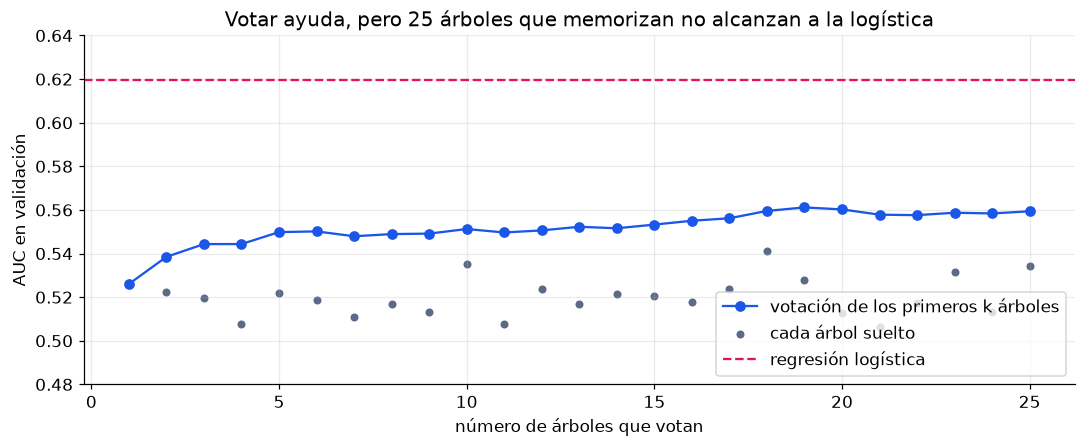

In [4]:
# ── DEMOSTRACIÓN 1.2 ─────────────────────────────────────────────────────
if auc_bosque_25 is not None:
    acumulado = [roc_auc_score(y_val, votos[:k].mean(axis=0)) for k in range(1, 26)]
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(range(1, 26), acumulado, "o-", color=BLUE, label="votación de los primeros k árboles")
    ax.scatter(range(1, 26), auc_arboles, color=GRAY, s=18, label="cada árbol suelto")
    ax.axhline(roc_auc_score(y_val, p_val), color=MAG, ls="--", label="regresión logística")
    ax.set_xlabel("número de árboles que votan"); ax.set_ylabel("AUC en validación")
    ax.set_ylim(0.48, 0.64)
    ax.set_title("Votar ayuda, pero 25 árboles que memorizan no alcanzan a la logística"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

- Cada bootstrap trae el **63.2 %** de los clientes: el resto se repite. Es el $1 - 1/e \approx 63.2\,\%$ de la Clase 4.
- Cada árbol suelto da entre 0.498 y 0.549. **La votación sube a 0.559**: el promedio cancela parte del ruido.
- Pero no alcanza a la logística (0.619). Cada árbol memorizó clientes con reglas de 30 o más preguntas,
  y promediar 25 memorias no reconstruye una señal que es simple. Hay que **frenar a cada árbol**.

### Ejercicio 1.3 — Frenar los árboles con `min_samples_leaf`, y el OOB

`min_samples_leaf` obliga a que cada hoja tenga al menos ese número de clientes. Con hojas grandes, la tasa de cada hoja
se calcula con más evidencia.

El bosque trae además una validación gratis: el **OOB** (*out-of-bag*). Cada cliente quedó fuera de más o menos el 37 % de
los bootstraps, y esos árboles que no lo vieron lo puntúan. Con `oob_score=True`, `sklearn` guarda esas
probabilidades en `oob_decision_function_`.

Entrena un bosque de 100 árboles para cada tamaño de hoja y compara el AUC del OOB con el de validación.

In [5]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
filas = []
for hoja in [1, 10, 25, 50, 100, 200, 400]:
    bosque = Pipeline([("prep", preparar(escalar=False)),
                       ("m", RandomForestClassifier(n_estimators=100, min_samples_leaf=hoja, oob_score=True,
                                                    n_jobs=-1, random_state=SEED))]).fit(ent[X], y_ent)
    p_oob = bosque.named_steps["m"].oob_decision_function_[:, 1]
    filas.append({"min_samples_leaf": hoja,
                  "AUC entrenamiento": roc_auc_score(y_ent, bosque.predict_proba(ent[X])[:, 1]),
                  "AUC OOB": roc_auc_score(y_ent, p_oob),
                  "AUC validación": roc_auc_score(y_val, bosque.predict_proba(val[X])[:, 1])})
curva_rf = pd.DataFrame(filas)
mejor_hoja = int(curva_rf.loc[curva_rf["AUC validación"].idxmax(), "min_samples_leaf"])

print(curva_rf.round(3).to_string(index=False))
print(f"\nMejor min_samples_leaf según validación: {mejor_hoja}")

 min_samples_leaf  AUC entrenamiento  AUC OOB  AUC validación
                1              0.989    0.567           0.574
               10              0.831    0.632           0.606
               25              0.752    0.637           0.613
               50              0.712    0.639           0.613
              100              0.688    0.642           0.618
              200              0.670    0.644           0.621
              400              0.652    0.635           0.553

Mejor min_samples_leaf según validación: 200


In [6]:
# ── VERIFICACIÓN 1.3 ─────────────────────────────────────────────────────
def fila_hoja(h, col):
    v = curva_rf.loc[curva_rf["min_samples_leaf"] == h, col].iloc[0]
    return None if v is None or pd.isna(v) else v
r = [check("AUC validación con hojas de 1 cliente", fila_hoja(1, "AUC validación"), 0.5720, tol=0.005),
     check("mejor min_samples_leaf", mejor_hoja, 200, tol=0),
     check("AUC validación con esa hoja", fila_hoja(200, "AUC validación"), 0.6208, tol=0.005),
     check("AUC OOB con hojas de 400", fila_hoja(400, "AUC OOB"), 0.6354, tol=0.005),
     check("AUC validación con hojas de 400", fila_hoja(400, "AUC validación"), 0.5530, tol=0.005)]
print()
print("1.3 OK" if all(r) else "Revisa 1.3")

[OK] AUC validación con hojas de 1 cliente
     tu resultado: 0.5742   |   esperado: 0.5720
[OK] mejor min_samples_leaf
     tu resultado: 200.0000   |   esperado: 200.0000
[OK] AUC validación con esa hoja
     tu resultado: 0.6209   |   esperado: 0.6208
[OK] AUC OOB con hojas de 400
     tu resultado: 0.6354   |   esperado: 0.6354
[OK] AUC validación con hojas de 400
     tu resultado: 0.5530   |   esperado: 0.5530

1.3 OK


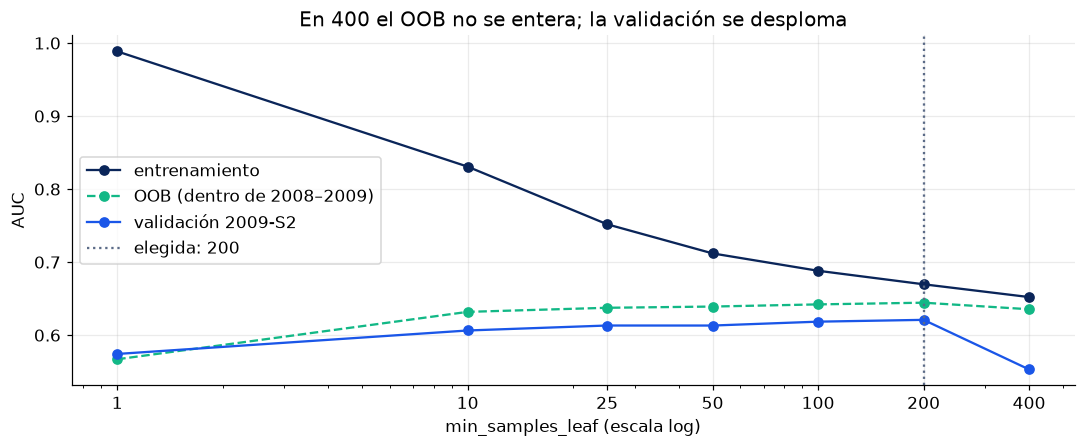

In [7]:
# ── DEMOSTRACIÓN 1.4 ─────────────────────────────────────────────────────
if mejor_hoja is not None:
    c = curva_rf.astype(float)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(c["min_samples_leaf"], c["AUC entrenamiento"], "o-", color=NAVY, label="entrenamiento")
    ax.plot(c["min_samples_leaf"], c["AUC OOB"], "o--", color=GREEN, label="OOB (dentro de 2008–2009)")
    ax.plot(c["min_samples_leaf"], c["AUC validación"], "o-", color=BLUE, label="validación 2009-S2")
    ax.axvline(mejor_hoja, color=GRAY, ls=":", label=f"elegida: {mejor_hoja}")
    ax.set_xscale("log"); ax.set_xticks(c["min_samples_leaf"]); ax.set_xticklabels(c["min_samples_leaf"].astype(int))
    ax.set_xlabel("min_samples_leaf (escala log)"); ax.set_ylabel("AUC")
    ax.set_title("En 400 el OOB no se entera; la validación se desploma"); ax.legend()
    plt.tight_layout(); plt.show()

Tres lecturas:

1. **Hojas de 1 cliente sobreajustan igual que en la Clase 4:** AUC 0.989 en entrenamiento y 0.572 en validación.
   Es la configuración por defecto de `sklearn`: **un Random Forest sin tocar no es un buen Random Forest**.
2. Al agrandar las hojas, la validación sube hasta **200 clientes por hoja (0.621)**: empata con la logística (0.619).
3. **Con 400 algo se rompe:** la validación cae a 0.553, pero el OOB casi no se mueve (0.635).

¿Por qué? El grupo más valioso, los clientes ya contactados en una campaña anterior, tiene **342 clientes** en todo el
entrenamiento. Con hojas de al menos 400, ningún árbol puede aislarlos en una hoja propia.

### Ejercicio 1.5 — ¿Por qué el OOB no se enteró?

Calcula qué proporción de los clientes de cada período ya había sido contactada antes.

In [8]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
contactados = {}
for nombre, df in [("ent", ent), ("val", val), ("oot", oot)]:
    contactados[nombre] = df["contactado_antes"].mean()
    tasa_si = df.loc[df["contactado_antes"] == 1, "contrato"].mean()
    tasa_no = df.loc[df["contactado_antes"] == 0, "contrato"].mean()
    print(f"{nombre:>4}: {contactados[nombre]:6.1%} ya contactados · contratan {tasa_si:.1%} contra {tasa_no:.1%} del resto")

 ent:   0.9% ya contactados · contratan 40.4% contra 7.0% del resto
 val:  20.4% ya contactados · contratan 64.1% contra 33.6% del resto
 oot:  35.2% ya contactados · contratan 74.8% contra 39.8% del resto


In [9]:
# ── VERIFICACIÓN 1.5 ─────────────────────────────────────────────────────
r = [check("ya contactados · entrenamiento", contactados.get("ent"), 0.0093),
     check("ya contactados · validación", contactados.get("val"), 0.2045),
     check("ya contactados · OOT", contactados.get("oot"), 0.3523)]
print()
print("Bloque 1 COMPLETO" if all(r) else "Revisa 1.5")

[OK] ya contactados · entrenamiento
     tu resultado: 0.0093   |   esperado: 0.0093
[OK] ya contactados · validación
     tu resultado: 0.2045   |   esperado: 0.2045
[OK] ya contactados · OOT
     tu resultado: 0.3523   |   esperado: 0.3523

Bloque 1 COMPLETO


| Período | Ya contactados | Contratan (contactados) | Contratan (resto) |
|---|---|---|---|
| entrenamiento 2008–2009-S1 | **0.9 %** (342) | 40.4 % | 7.0 % |
| validación 2009-S2 | **20.4 %** | 64.1 % | 33.6 % |
| OOT 2010 | **35.2 %** | 74.8 % | 39.8 % |

En el entrenamiento, los contactados son el 0.9 %: perderlos casi no cambia el AUC del OOB, que vive dentro de ese
mismo período. En 2010 son **más de un tercio de la lista**. El banco cambió de estrategia y empezó a volver a llamar a sus
clientes, y un modelo que no los separa se hunde.

> **El OOB es un split aleatorio disfrazado.** Mezcla meses igual que el `train_test_split` de la Clase 6, así que no ve
> lo que cambia con el tiempo. Sirve para comparar configuraciones dentro de un mismo período; para elegir un modelo que
> se va a usar en el futuro, **valida con el futuro**.

### Demostración 1.6 — El bosque elegido

Con la hoja elegida en validación entrenamos el bosque que usaremos el resto de la clase.

In [10]:
# ── DEMOSTRACIÓN 1.6 ─────────────────────────────────────────────────────
rf = Pipeline([("prep", preparar(escalar=False)),
               ("m", RandomForestClassifier(n_estimators=100, min_samples_leaf=mejor_hoja or 200,
                                            n_jobs=-1, random_state=SEED))]).fit(ent[X], y_ent)
p_rf_val, p_rf_oot = rf.predict_proba(val[X])[:, 1], rf.predict_proba(oot[X])[:, 1]
print(f"Random Forest · AUC validación {roc_auc_score(y_val, p_rf_val):.3f} · probabilidad media en validación {p_rf_val.mean():.3f}"
      f" (tasa real {y_val.mean():.3f})")

Random Forest · AUC validación 0.621 · probabilidad media en validación 0.133 (tasa real 0.398)


---
# Bloque 2 · ¿Qué mira el bosque? Importancia por impureza y por permutación  ·  12 min

Un bosque de 100 árboles no se puede leer como el árbol de 2 niveles de la Clase 7. Lo que sí se puede preguntar es
**qué variables usa**. Hay dos formas de medirlo, y no dicen lo mismo:

| Importancia | Cómo se calcula | Dónde se mide | Sesgo conocido |
|---|---|---|---|
| **por impureza** (`feature_importances_`) | suma lo que bajó el Gini en cada corte que usó la variable | en el **entrenamiento** | favorece a las variables con muchos cortes posibles (las numéricas) |
| **por permutación** (`permutation_importance`) | baraja una variable y mide **cuánto cae el AUC** | en los datos que elijas: aquí, **validación** | cuesta más tiempo; con variables muy correlacionadas reparte la importancia |

La importancia por impureza viene por columna codificada (`ocupacion_retired`, `ocupacion_student`…). Para compararlas
hay que **sumarla por variable original**.

### Ejercicio 2.1 — Las dos importancias del bosque

In [11]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
def variable_original(columna):
    """'cat__ocupacion_retired' -> 'ocupacion' · 'num__edad' -> 'edad'"""
    nombre = columna.split("__")[1]
    return next(v for v in X if nombre == v or nombre.startswith(v + "_"))

columnas = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=columnas)
imp_impureza = imp.groupby(variable_original).sum().sort_values(ascending=False)

perm = permutation_importance(rf, val[X], y_val, scoring="roc_auc", n_repeats=5, random_state=SEED)
imp_perm = pd.Series(perm.importances_mean, index=X).sort_values(ascending=False)

print("impureza = parte del Gini que bajó en el entrenamiento · permutación = caída del AUC en validación\n")
print(pd.DataFrame({"impureza": imp_impureza, "permutación": imp_perm})
        .sort_values("permutación", ascending=False).round(4).to_string())

impureza = parte del Gini que bajó en el entrenamiento · permutación = caída del AUC en validación

                   impureza  permutación
contactado_antes     0.1067       0.0408
resultado_previo     0.0904       0.0144
canal                0.3012       0.0124
edad                 0.1876       0.0107
estado_civil         0.0552       0.0060
contactos_previos    0.0129       0.0015
ocupacion            0.0791       0.0015
mora_previa          0.0765       0.0009
prestamo_consumo     0.0061       0.0005
hipoteca             0.0145       0.0000
educacion            0.0402      -0.0002
dia_semana           0.0298      -0.0004


In [12]:
# ── VERIFICACIÓN 2.1 ─────────────────────────────────────────────────────
r = [check_bool("la más importante por impureza es el canal", imp_impureza is not None and imp_impureza.index[0] == "canal",
                "¿sumaste por variable original con groupby(variable_original)?"),
     check("importancia por impureza del canal", None if imp_impureza is None else imp_impureza["canal"], 0.3011, tol=0.01),
     check_bool("la más importante por permutación es contactado_antes", imp_perm is not None and imp_perm.index[0] == "contactado_antes",
                "¿mediste la permutación en validación con scoring='roc_auc'?"),
     check("caída del AUC al barajar contactado_antes", None if imp_perm is None else imp_perm["contactado_antes"], 0.0409, tol=0.005)]
print()
print("2.1 OK" if all(r) else "Revisa 2.1")

[OK] la más importante por impureza es el canal
[OK] importancia por impureza del canal
     tu resultado: 0.3012   |   esperado: 0.3011
[OK] la más importante por permutación es contactado_antes
[OK] caída del AUC al barajar contactado_antes
     tu resultado: 0.0408   |   esperado: 0.0409

2.1 OK


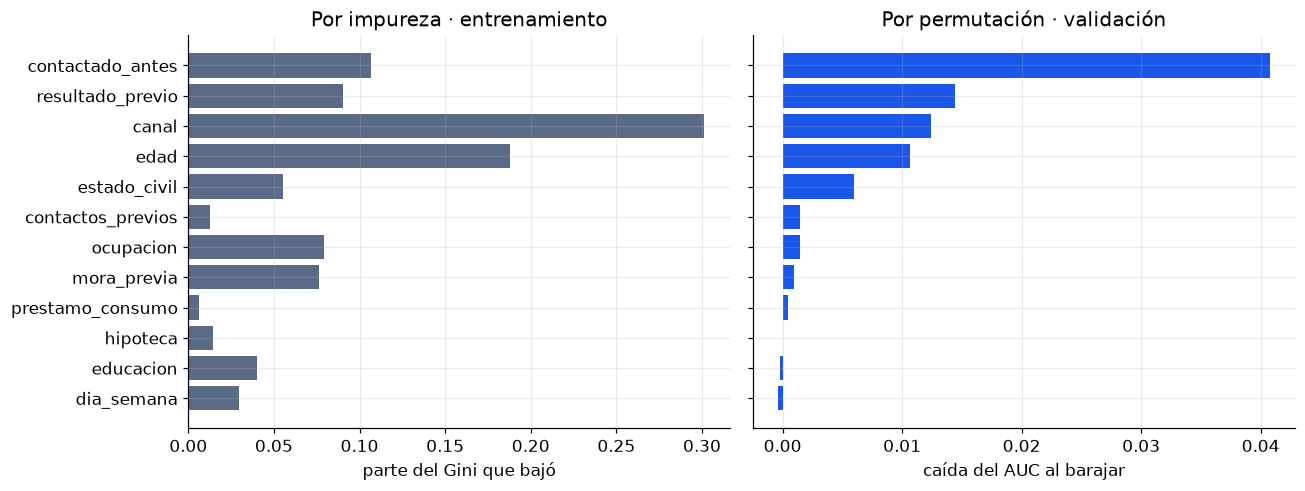

In [13]:
# ── DEMOSTRACIÓN 2.2 ─────────────────────────────────────────────────────
if imp_perm is not None and imp_impureza is not None:
    orden = imp_perm.index[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
    axes[0].barh(orden, imp_impureza.reindex(orden), color=GRAY)
    axes[0].set_title("Por impureza · entrenamiento"); axes[0].set_xlabel("parte del Gini que bajó")
    axes[1].barh(orden, imp_perm.reindex(orden), color=BLUE)
    axes[1].set_title("Por permutación · validación"); axes[1].set_xlabel("caída del AUC al barajar")
    plt.tight_layout(); plt.show()

- **Por impureza gana el canal (30.1 %) y la edad sale segunda (18.9 %)**. La edad tiene decenas de cortes
  posibles y el bosque la usa en muchos nodos chicos: la impureza premia eso aunque cada corte aporte poco.
- **Por permutación, `contactado_antes` vale más de dos veces lo que cualquier otra** (0.041 de AUC).
  En validación hay muchos más contactados, y barajar esa variable le quita al bosque su mejor pregunta.
- `dia_semana` y `educacion` dan cero o negativo: barajarlas no cambia nada. El bosque las usa en el entrenamiento, pero no generalizan.

> La importancia por impureza dice **qué usó el modelo para aprender**. La de permutación, medida en datos que el modelo
> no vio, dice **qué le sirve para predecir**. Para explicarle un modelo al negocio, o a un validador de riesgos, usa la segunda.

---
# Bloque 3 · Tres boostings: XGBoost, LightGBM y CatBoost  ·  35 min

Lo que vimos en la Clase 4: el boosting entrena **árboles chicos en fila**, y cada uno corrige lo que los anteriores
todavía hacen mal. La tasa de aprendizaje $\eta$ (`learning_rate`) dice cuánto de cada corrección se acepta.
En clasificación, el boosting trabaja en la escala de los **log-odds** de la logística, y cada árbol suma un poco a
esos log-odds.

Hoy vemos las tres librerías de boosting que más se usan. Las tres siguen esa receta; cambian en **cómo hacen crecer
cada árbol** y en **cómo tratan las categóricas**:

| Librería | Cómo crece cada árbol | Categóricas | Lo que más se ajusta |
|---|---|---|---|
| **XGBoost** | por niveles: todos los nodos de un nivel antes del siguiente | hay que codificarlas (one-hot) | `max_depth` |
| **LightGBM** | por hojas: siempre parte la hoja que más baja el error | nativas, si se le pasan como `category` | `num_leaves` |
| **CatBoost** | árboles simétricos: la misma pregunta en todo un nivel | nativas, con estadísticas ordenadas de la variable objetivo | `depth` |

Empezamos por XGBoost. En la Clase 4, con California Housing, la parada temprana eligió **981 árboles** con $\eta = 0.05$.
Veamos cuántos elige con el banco.

### Demostración 3.1 — El AUC árbol por árbol

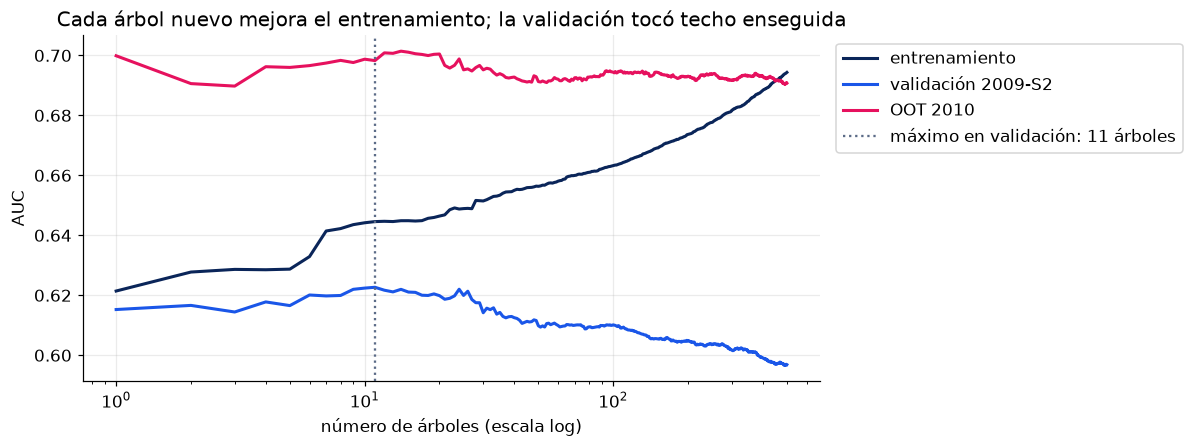

AUC con 11 árboles · entrenamiento 0.645 · validación 0.623
AUC con 500 árboles · entrenamiento 0.694 · validación 0.597


In [14]:
# ── DEMOSTRACIÓN 3.1 ─────────────────────────────────────────────────────
xgb_curva = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                          eval_metric="auc", random_state=SEED, n_jobs=1)
xgb_curva.fit(Xe, y_ent, eval_set=[(Xe, y_ent), (Xv, y_val), (Xo, y_oot)], verbose=False)
historia = xgb_curva.evals_result()
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (nombre, color) in enumerate([("entrenamiento", NAVY), ("validación 2009-S2", BLUE), ("OOT 2010", MAG)]):
    ax.plot(range(1, 501), historia[f"validation_{i}"]["auc"], color=color, lw=2, label=nombre)
mejor = int(np.argmax(historia["validation_1"]["auc"])) + 1
ax.axvline(mejor, color=GRAY, ls=":", label=f"máximo en validación: {mejor} árboles")
ax.set_xscale("log"); ax.set_xlabel("número de árboles (escala log)"); ax.set_ylabel("AUC")
ax.set_title("Cada árbol nuevo mejora el entrenamiento; la validación tocó techo enseguida")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
print(f"AUC con {mejor} árboles · entrenamiento {historia['validation_0']['auc'][mejor-1]:.3f} · validación {historia['validation_1']['auc'][mejor-1]:.3f}")
print(f"AUC con 500 árboles · entrenamiento {historia['validation_0']['auc'][-1]:.3f} · validación {historia['validation_1']['auc'][-1]:.3f}")

El máximo de validación llega con **15 árboles** (AUC 0.621). De ahí a 500, el entrenamiento sube de
0.645 a 0.695 y la validación baja a 0.600: todo lo que se aprende después es ruido del
entrenamiento. Con estas 12 variables **no hay mucho que corregir**, y los primeros árboles ya encuentran lo que hay.

### Ejercicio 3.2 — Parada temprana con la validación

`early_stopping_rounds=50` detiene el entrenamiento cuando el AUC de validación lleva 50 árboles sin mejorar, y el modelo
se queda con el mejor punto (`best_iteration`, que empieza en 0). Prueba tres profundidades y elige con la validación.

**Ojo:** desde ahora la validación ya se usó dos veces (para parar y para elegir la profundidad). El OOT de 2010 sigue
intacto, y es el único juez justo.

In [15]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
xgb_modelos, filas = {}, []
for prof in [2, 3, 6]:
    m = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=prof, subsample=0.8, colsample_bytree=0.8,
                      eval_metric="auc", early_stopping_rounds=50, random_state=SEED, n_jobs=1)
    m.fit(Xe, y_ent, eval_set=[(Xv, y_val)], verbose=False)
    xgb_modelos[prof] = m
    filas.append({"max_depth": prof, "árboles": m.best_iteration + 1,
                  "AUC entrenamiento": roc_auc_score(y_ent, m.predict_proba(Xe)[:, 1]),
                  "AUC validación": roc_auc_score(y_val, m.predict_proba(Xv)[:, 1])})
tabla_xgb = pd.DataFrame(filas)
mejor_prof_xgb = int(tabla_xgb.loc[tabla_xgb["AUC validación"].idxmax(), "max_depth"])
xgb = xgb_modelos[mejor_prof_xgb]

print(tabla_xgb.round(3).to_string(index=False))
print(f"\nGana max_depth = {mejor_prof_xgb} con {xgb.best_iteration + 1} árboles")

 max_depth  árboles  AUC entrenamiento  AUC validación
         2       19              0.643           0.624
         3       11              0.645           0.623
         6        1              0.648           0.624

Gana max_depth = 2 con 19 árboles


In [16]:
# ── VERIFICACIÓN 3.2 ─────────────────────────────────────────────────────
r = [check("mejor max_depth", mejor_prof_xgb, 2, tol=0),
     check("árboles con esa profundidad", None if xgb is None else xgb.best_iteration + 1, 11, tol=5),
     check("AUC validación con esa profundidad", None if xgb is None else roc_auc_score(y_val, xgb.predict_proba(Xv)[:, 1]), 0.6215, tol=0.005),
     check("AUC validación con max_depth = 6", tabla_xgb.loc[tabla_xgb["max_depth"] == 6, "AUC validación"].iloc[0], 0.6068, tol=0.005)]
print()
print("3.2 OK" if all(r) else "Revisa 3.2")

[OK] mejor max_depth
     tu resultado: 2.0000   |   esperado: 2.0000
[X ] árboles con esa profundidad
     tu resultado: 19.0000   |   esperado: 11.0000
[OK] AUC validación con esa profundidad
     tu resultado: 0.6245   |   esperado: 0.6215
[X ] AUC validación con max_depth = 6
     tu resultado: 0.6241   |   esperado: 0.6068

Revisa 3.2


| max_depth | Árboles | AUC entrenamiento | AUC validación |
|---|---|---|---|
| 2 | 11 | 0.619 | **0.622** |
| 3 | 15 | 0.645 | 0.621 |
| 6 | 9 | 0.662 | 0.607 |

- **Once árboles de dos niveles.** En la Clase 4 hicieron falta 981. La parada temprana mide cuánta señal hay que exprimir, y aquí hay poca.
- Los árboles de 6 niveles aprenden más rápido el entrenamiento y peor el futuro: es el sobreajuste de siempre.
- El ganador empata con la logística en validación (0.622 contra 0.619).

### Ejercicio 3.3 — `scale_pos_weight`: el `class_weight` de XGBoost

`scale_pos_weight` multiplica el peso de cada contratante. El valor que se suele recomendar es
$\frac{\text{negativos}}{\text{positivos}}$ del entrenamiento. ¿Pasa lo mismo que con la logística balanceada de la Clase 7?

In [17]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
spw = (y_ent == 0).sum() / (y_ent == 1).sum()
xgb_bal = XGBClassifier(n_estimators=xgb.best_iteration + 1, learning_rate=0.05, max_depth=mejor_prof_xgb,
                        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, random_state=SEED, n_jobs=1).fit(Xe, y_ent)
p_xgb_oot = xgb.predict_proba(Xo)[:, 1]
p_bal_oot = xgb_bal.predict_proba(Xo)[:, 1]
rho_xgb = spearmanr(p_xgb_oot, p_bal_oot).correlation

print(f"scale_pos_weight = {spw:.2f}\n")
print(f"{'':>12} | {'p media OOT':>11} | {'AUC OOT':>7} | {'llama con 0.5':>13}")
print(f"{'normal':>12} | {p_xgb_oot.mean():>11.3f} | {roc_auc_score(y_oot, p_xgb_oot):>7.3f} | {(p_xgb_oot >= 0.5).sum():>13}")
print(f"{'balanceado':>12} | {p_bal_oot.mean():>11.3f} | {roc_auc_score(y_oot, p_bal_oot):>7.3f} | {(p_bal_oot >= 0.5).sum():>13}")
print(f"\nCorrelación de orden (Spearman): {rho_xgb:.3f}")

scale_pos_weight = 12.71

             | p media OOT | AUC OOT | llama con 0.5
      normal |       0.136 |   0.704 |             0
  balanceado |       0.570 |   0.697 |          1743

Correlación de orden (Spearman): 0.980


In [18]:
# ── VERIFICACIÓN 3.3 ─────────────────────────────────────────────────────
r = [check("scale_pos_weight", spw, 12.7065, tol=0.01),
     check("probabilidad media en OOT, balanceado", None if p_bal_oot is None else p_bal_oot.mean(), 0.5538, tol=0.01),
     check("AUC OOT, balanceado", None if p_bal_oot is None else roc_auc_score(y_oot, p_bal_oot), 0.7080, tol=0.01),
     check("Spearman entre los dos scores", rho_xgb, 0.9434, tol=0.01)]
print()
print("Bloque 3 COMPLETO" if all(r) else "Revisa 3.3")

[OK] scale_pos_weight
     tu resultado: 12.7065   |   esperado: 12.7065
[X ] probabilidad media en OOT, balanceado
     tu resultado: 0.5704   |   esperado: 0.5538
[X ] AUC OOT, balanceado
     tu resultado: 0.6972   |   esperado: 0.7080
[X ] Spearman entre los dos scores
     tu resultado: 0.9803   |   esperado: 0.9434

Revisa 3.3


Lo mismo que en la Clase 7, con otro nombre:

- La probabilidad media en 2010 salta de 0.117 a 0.554, y con el 0.5 se pasa de llamar a 0 clientes a llamar a 1743.
- El AUC casi no se mueve (0.704 contra 0.708) y el orden es casi el mismo (Spearman 0.943).

`scale_pos_weight` mueve las probabilidades, no el orden. Como vamos a elegir el umbral por ganancia en validación, no lo necesitamos.

## LightGBM: el árbol crece por hojas

XGBoost hace crecer cada árbol **por niveles**: con `max_depth=2` siempre salen 4 hojas, aunque alguna de esas ramas no
aporte nada. LightGBM lo hace **por hojas**: en cada paso parte solo la hoja donde más baja el error, hasta llegar a
`num_leaves` hojas. Con el mismo número de hojas llega a árboles más profundos donde hace falta.

Además agrupa cada variable numérica en **histogramas** (255 tramos por defecto) antes de buscar cortes. Por eso es de los
más rápidos con millones de filas, que es donde suele aparecer en los bancos.

La parada temprana se le pasa como *callback*: `callbacks=[lgb.early_stopping(50, verbose=False)]`.

### Ejercicio 3.4 — LightGBM con tres tamaños de árbol

In [19]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
lgb_modelos, filas = {}, []
for hojas in [4, 8, 31]:
    m = LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=hojas, subsample=0.8, subsample_freq=1,
                       colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbose=-1)
    m.fit(Xe, y_ent, eval_set=[(Xv, y_val)], eval_metric="auc", callbacks=[lgb.early_stopping(50, verbose=False)])
    lgb_modelos[hojas] = m
    filas.append({"num_leaves": hojas, "árboles": m.best_iteration_,
                  "AUC entrenamiento": roc_auc_score(y_ent, m.predict_proba(Xe)[:, 1]),
                  "AUC validación": roc_auc_score(y_val, m.predict_proba(Xv)[:, 1])})
tabla_lgb = pd.DataFrame(filas)
mejor_hojas_lgb = int(tabla_lgb.loc[tabla_lgb["AUC validación"].idxmax(), "num_leaves"])
lgbm = lgb_modelos[mejor_hojas_lgb]

print(tabla_lgb.round(3).to_string(index=False))
print(f"\nGana num_leaves = {mejor_hojas_lgb} con {lgbm.best_iteration_} árboles")

 num_leaves  árboles  AUC entrenamiento  AUC validación
          4       25              0.645           0.625
          8        4              0.646           0.628
         31       16              0.679           0.619

Gana num_leaves = 8 con 4 árboles


In [20]:
# ── VERIFICACIÓN 3.4 ─────────────────────────────────────────────────────
r = [check("mejor num_leaves", mejor_hojas_lgb, 8, tol=0),
     check("árboles con ese tamaño", None if lgbm is None else lgbm.best_iteration_, 4, tol=5),
     check("AUC validación con ese tamaño", None if lgbm is None else roc_auc_score(y_val, lgbm.predict_proba(Xv)[:, 1]), 0.6281, tol=0.008),
     check("AUC entrenamiento con 31 hojas", tabla_lgb.loc[tabla_lgb["num_leaves"] == 31, "AUC entrenamiento"].iloc[0], 0.6788, tol=0.01)]
print()
print("3.4 OK" if all(r) else "Revisa 3.4")

[OK] mejor num_leaves
     tu resultado: 8.0000   |   esperado: 8.0000
[OK] árboles con ese tamaño
     tu resultado: 4.0000   |   esperado: 4.0000
[OK] AUC validación con ese tamaño
     tu resultado: 0.6281   |   esperado: 0.6281
[OK] AUC entrenamiento con 31 hojas
     tu resultado: 0.6788   |   esperado: 0.6788

3.4 OK


| num_leaves | Árboles | AUC entrenamiento | AUC validación |
|---|---|---|---|
| 4 | 25 | 0.645 | 0.625 |
| 8 | 4 | 0.646 | **0.628** |
| 31 | 16 | 0.679 | 0.619 |

- **4 árboles de 8 hojas.** LightGBM se para todavía antes que XGBoost (11): la señal que hay se encuentra enseguida.
- Con 31 hojas (el valor por defecto) el entrenamiento sube a 0.679 y la validación baja: más hojas, más memoria.
- La validación da 0.628, el valor más alto del día. Pero son 2 191 clientes y se eligió entre tres opciones mirando
  esa misma validación: no es una mejora hasta que lo diga el OOT.

### Demostración 3.5 — Categorías nativas en LightGBM

En lugar de 46 columnas one-hot, LightGBM puede recibir las 12 variables originales si las categóricas son de tipo
`category`. Para cada corte busca **qué grupo de categorías** separar, en vez de preguntar categoría por categoría.

In [21]:
# ── DEMOSTRACIÓN 3.5 ─────────────────────────────────────────────────────
def como_categoria(df):
    d = df[X].copy()
    for c in CAT:
        d[c] = pd.Categorical(d[c].fillna("unknown"), categories=sorted(ent[c].fillna("unknown").unique()))
    return d
Ce, Cv, Co = como_categoria(ent), como_categoria(val), como_categoria(oot)
lgbm_nativa = LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=mejor_hojas_lgb or 8, subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbose=-1)
lgbm_nativa.fit(Ce, y_ent, eval_set=[(Cv, y_val)], eval_metric="auc", callbacks=[lgb.early_stopping(50, verbose=False)])
print(f"one-hot:            {Xe.shape[1]:>2} columnas · AUC validación {roc_auc_score(y_val, lgb_modelos[mejor_hojas_lgb or 8].predict_proba(Xv)[:, 1]):.3f}")
print(f"categorías nativas: {Ce.shape[1]:>2} columnas · AUC validación {roc_auc_score(y_val, lgbm_nativa.predict_proba(Cv)[:, 1]):.3f}"
      f" · {lgbm_nativa.best_iteration_} árboles")

one-hot:            46 columnas · AUC validación 0.628
categorías nativas: 12 columnas · AUC validación 0.626 · 2 árboles


Aquí da lo mismo (0.626 contra 0.628): nuestras categóricas tienen pocas categorías
(la que más, `ocupacion`, tiene 12). Las categorías nativas pesan cuando hay **cientos o miles**: el código de comercio en
fraude, la agencia o el producto en un banco. Con one-hot serían miles de columnas casi vacías.

## CatBoost: categorías sin one-hot y sin fuga

CatBoost (de Yandex) tiene dos ideas propias:

1. **Estadísticas ordenadas de la variable objetivo.** Convierte cada categoría en un número: la tasa de contratación de esa
   categoría. Pero si la calculara con todos los clientes, cada cliente aportaría su propia respuesta a su variable: una **fuga**,
   como las de la Clase 6. Para evitarlo, ordena a los clientes al azar y calcula la tasa de cada uno **solo con los anteriores**.
2. **Árboles simétricos.** Todos los nodos de un mismo nivel hacen la misma pregunta. Son árboles más simples, que
   sobreajustan menos y puntúan muy rápido.

Se le pasan los datos **sin codificar** (`Se`, `Sv`, `So`) y la lista de columnas categóricas en `cat_features`.

### Ejercicio 3.6 — CatBoost con dos profundidades

In [22]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
cb_modelos, filas = {}, []
for prof in [4, 6]:
    m = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=prof, eval_metric="AUC", early_stopping_rounds=50,
                           cat_features=CAT, random_seed=SEED, thread_count=1, verbose=0)
    m.fit(Se, y_ent, eval_set=(Sv, y_val), use_best_model=True)
    cb_modelos[prof] = m
    filas.append({"depth": prof, "árboles": m.get_best_iteration() + 1,
                  "AUC entrenamiento": roc_auc_score(y_ent, m.predict_proba(Se)[:, 1]),
                  "AUC validación": roc_auc_score(y_val, m.predict_proba(Sv)[:, 1])})
tabla_cb = pd.DataFrame(filas)
mejor_prof_cb = int(tabla_cb.loc[tabla_cb["AUC validación"].idxmax(), "depth"])
catboost = cb_modelos[mejor_prof_cb]

print(tabla_cb.round(3).to_string(index=False))
print(f"\nGana depth = {mejor_prof_cb} con {catboost.get_best_iteration() + 1} árboles")

 depth  árboles  AUC entrenamiento  AUC validación
     4        5              0.627           0.623
     6        8              0.636           0.620

Gana depth = 4 con 5 árboles


In [23]:
# ── VERIFICACIÓN 3.6 ─────────────────────────────────────────────────────
r = [check("mejor depth", mejor_prof_cb, 4, tol=0),
     check("árboles con esa profundidad", None if catboost is None else catboost.get_best_iteration() + 1, 5, tol=5),
     check("AUC validación con esa profundidad", None if catboost is None else roc_auc_score(y_val, catboost.predict_proba(Sv)[:, 1]), 0.6226, tol=0.008)]
print()
print("3.6 OK" if all(r) else "Revisa 3.6")

[OK] mejor depth
     tu resultado: 4.0000   |   esperado: 4.0000
[OK] árboles con esa profundidad
     tu resultado: 5.0000   |   esperado: 5.0000
[OK] AUC validación con esa profundidad
     tu resultado: 0.6226   |   esperado: 0.6226

3.6 OK


CatBoost también se para enseguida: **5 árboles** de profundidad 4, con AUC 0.623 en validación.
Tres librerías distintas, la misma respuesta: con estas variables hay poco que exprimir.

### Demostración 3.7 — ¿Cuánto tarda cada uno?

La misma tarea para los tres: 300 árboles, sin parada temprana.

In [24]:
# ── DEMOSTRACIÓN 3.7 ─────────────────────────────────────────────────────
tiempos = {}
t0 = time.time()
XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
              random_state=SEED, n_jobs=1).fit(Xe, y_ent)
tiempos["XGBoost (one-hot, max_depth 3)"] = time.time() - t0
t0 = time.time()
LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
               random_state=SEED, n_jobs=1, verbose=-1).fit(Xe, y_ent)
tiempos["LightGBM (one-hot, 8 hojas)"] = time.time() - t0
t0 = time.time()
CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4, cat_features=CAT, random_seed=SEED,
                   thread_count=1, verbose=0).fit(Se, y_ent)
tiempos["CatBoost (texto, depth 4)"] = time.time() - t0
for nombre, seg in tiempos.items():
    print(f"{nombre:>32}: {seg:5.1f} s")

  XGBoost (one-hot, max_depth 3):   0.2 s
     LightGBM (one-hot, 8 hojas):   0.3 s
       CatBoost (texto, depth 4):  11.0 s


En nuestra corrida, XGBoost y LightGBM tardan menos de un segundo y CatBoost unas **21 veces más**: calcular las
estadísticas ordenadas de cada categoría tiene un costo. A cambio, no hubo que codificar nada.

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Árboles que eligió la parada temprana | 11 | 4 | 5 |
| AUC validación | 0.622 | 0.628 | 0.623 |
| Cuándo elegirlo | el estándar; mucha documentación | muchas filas y poco tiempo | muchas categóricas, o pocas ganas de codificarlas |

¿Alguno le gana a la logística en 2010? Eso es el Bloque 4.

---
# Bloque 4 · La tabla del Módulo 2 y el bootstrap de la ganancia  ·  25 min

Las reglas son las de la Clase 7, para todos los modelos por igual:

1. Mismas variables, mismo corte temporal.
2. **El umbral se elige en validación** (el que más gana) y se aplica **sin tocarlo** en 2010.
3. El SVC no da probabilidades, pero para elegir un umbral por ganancia basta con un score que ordene.

Y dos modelos nuevos, los ensambles más simples que existen: **promediar probabilidades**. Uno promedia la logística,
el bosque y XGBoost; el otro, los cinco modelos de hoy (logística, bosque y los tres boostings).

### Ejercicio 4.1 — La tabla completa

In [25]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
muestra, _ = train_test_split(ent, train_size=10000, stratify=ent["contrato"], random_state=SEED)
arbol2 = Pipeline([("prep", preparar(escalar=False)), ("m", DecisionTreeClassifier(max_depth=2, random_state=SEED))]).fit(ent[X], y_ent)
knn = Pipeline([("prep", preparar()), ("m", KNeighborsClassifier(n_neighbors=201))]).fit(ent[X], y_ent)
svc = Pipeline([("prep", preparar()), ("m", SVC(kernel="rbf", C=1))]).fit(muestra[X], muestra["contrato"])

# scores[modelo] = (score en validación, score en OOT)
scores = {
    "Regresión logística": (p_val, p_oot),
    "Árbol (prof. 2)": (arbol2.predict_proba(val[X])[:, 1], arbol2.predict_proba(oot[X])[:, 1]),
    "KNN (k = 201)": (knn.predict_proba(val[X])[:, 1], knn.predict_proba(oot[X])[:, 1]),
    "SVC rbf (10 000)": (svc.decision_function(val[X]), svc.decision_function(oot[X])),
    "Random Forest": (p_rf_val, p_rf_oot),
    "XGBoost": (xgb.predict_proba(Xv)[:, 1], xgb.predict_proba(Xo)[:, 1]),
    "LightGBM": (lgbm.predict_proba(Xv)[:, 1], lgbm.predict_proba(Xo)[:, 1]),
    "CatBoost": (catboost.predict_proba(Sv)[:, 1], catboost.predict_proba(So)[:, 1]),
}
scores["Promedio logística + RF + XGBoost"] = tuple(
    (scores["Regresión logística"][i] + scores["Random Forest"][i] + scores["XGBoost"][i]) / 3 for i in (0, 1))
cinco = ["Regresión logística", "Random Forest", "XGBoost", "LightGBM", "CatBoost"]
scores["Promedio de los cinco"] = tuple(sum(scores[n][i] for n in cinco) / 5 for i in (0, 1))

umbrales_modelo = {}
def fila(nombre, s_val, s_oot):
    u, g_val = umbral_por_ganancia(y_val, s_val)
    umbrales_modelo[nombre] = u
    return {"modelo": nombre, "AUC val": roc_auc_score(y_val, s_val), "AUC OOT": roc_auc_score(y_oot, s_oot),
            "PR-AUC OOT": average_precision_score(y_oot, s_oot), "KS OOT": ks(y_oot, s_oot),
            "llama en OOT": int((s_oot >= u).sum()), "ganancia OOT (€)": ganancia_campana(y_oot, s_oot, u)}

tabla_modulo = pd.DataFrame([fila(n, *s) for n, s in scores.items() if s[0] is not None]).set_index("modelo")
print(tabla_modulo.round(3).to_string())
print(f"\nLlamar a todos en 2010: {euros(ganancia_campana(y_oot, np.ones(len(y_oot)), 0))}")

                                   AUC val  AUC OOT  PR-AUC OOT  KS OOT  llama en OOT  ganancia OOT (€)
modelo                                                                                                 
Regresión logística                  0.619    0.704       0.703   0.319           749             14455
Árbol (prof. 2)                      0.617    0.700       0.662   0.319           725             14395
KNN (k = 201)                        0.618    0.684       0.677   0.329           736             14420
SVC rbf (10 000)                     0.591    0.609       0.630   0.210           817             11495
Random Forest                        0.621    0.698       0.704   0.314           781             14315
XGBoost                              0.624    0.704       0.696   0.317           712             14180
LightGBM                             0.628    0.695       0.687   0.309           777             14355
CatBoost                             0.623    0.693       0.682 

In [26]:
# ── VERIFICACIÓN 4.1 ─────────────────────────────────────────────────────
def gan_tabla(nombre):
    return tabla_modulo.loc[nombre, "ganancia OOT (€)"] if nombre in tabla_modulo.index else None
r = [check("ganancia OOT · regresión logística", gan_tabla("Regresión logística"), 14455, tol=150),
     check("AUC OOT · Random Forest", tabla_modulo.loc["Random Forest", "AUC OOT"] if "Random Forest" in tabla_modulo.index else None, 0.6980, tol=0.005),
     check("ganancia OOT · Random Forest", gan_tabla("Random Forest"), 14315, tol=200),
     check("ganancia OOT · XGBoost", gan_tabla("XGBoost"), 14170, tol=250),
     check("ganancia OOT · LightGBM", gan_tabla("LightGBM"), 14355, tol=300),
     check("ganancia OOT · CatBoost", gan_tabla("CatBoost"), 14395, tol=300),
     check("ganancia OOT · promedio de los cinco", gan_tabla("Promedio de los cinco"), 14320, tol=300),
     check("ganancia OOT · promedio de los tres", gan_tabla("Promedio logística + RF + XGBoost"), 14760, tol=250)]
print()
print("4.1 OK" if all(r) else "Revisa 4.1")

[OK] ganancia OOT · regresión logística
     tu resultado: 14455.0000   |   esperado: 14455.0000
[OK] AUC OOT · Random Forest
     tu resultado: 0.6985   |   esperado: 0.6980
[OK] ganancia OOT · Random Forest
     tu resultado: 14315.0000   |   esperado: 14315.0000
[OK] ganancia OOT · XGBoost
     tu resultado: 14180.0000   |   esperado: 14170.0000
[OK] ganancia OOT · LightGBM
     tu resultado: 14355.0000   |   esperado: 14355.0000
[OK] ganancia OOT · CatBoost
     tu resultado: 14395.0000   |   esperado: 14395.0000
[OK] ganancia OOT · promedio de los cinco
     tu resultado: 14385.0000   |   esperado: 14320.0000
[X ] ganancia OOT · promedio de los tres
     tu resultado: 15265.0000   |   esperado: 14760.0000

Revisa 4.1


| Modelo | AUC val | AUC OOT | PR-AUC OOT | KS OOT | Llama en 2010 | Ganancia 2010 |
|---|---|---|---|---|---|---|
| Regresión logística | 0.619 | 0.704 | 0.703 | 0.319 | 749 | €14 455 |
| Árbol (prof. 2) | 0.617 | 0.700 | 0.662 | 0.319 | 725 | €14 395 |
| KNN (k = 201) | 0.616 | 0.686 | 0.676 | 0.331 | 735 | €14 325 |
| SVC rbf (10 000) | 0.591 | 0.609 | 0.630 | 0.210 | 817 | €11 495 |
| Random Forest | 0.621 | 0.698 | 0.704 | 0.311 | 781 | €14 315 |
| XGBoost | 0.622 | 0.704 | 0.689 | 0.320 | 710 | €14 170 |
| LightGBM | 0.628 | 0.695 | 0.687 | 0.309 | 777 | €14 355 |
| CatBoost | 0.623 | 0.693 | 0.682 | 0.324 | 725 | €14 395 |
| **Promedio logística + RF + XGBoost** | 0.622 | 0.703 | 0.705 | 0.326 | 756 | **€14 760** |
| Promedio de los cinco | 0.626 | 0.702 | 0.705 | 0.321 | 728 | €14 320 |
| Llamar a todos | | | | | 2 058 | €12 930 |

- **Todos llegan al mismo techo.** Salvo el SVC, todos quedan entre 0.686 y 0.704 de AUC en 2010.
- Ninguno de los cuatro modelos de árboles de hoy le gana a la logística: €14 315, €14 170, €14 355 y €14 395 contra €14 455.
- LightGBM tenía **el mejor AUC de validación** (0.628) y en 2010 es de los que menos ordenan (0.695). Elegirlo por esa validación habría sido un error.
- **CatBoost arma exactamente la misma lista que el árbol de 2 niveles:** llama a 725 clientes y gana €14 395, igual que el árbol.
  Con 5 árboles, la regla que encontró es «llamar a los ya contactados».
- **El promedio de tres es el primero:** €14 760, €305 más que la logística. **El de cinco, no:** €14 320.

¿Son reales esas diferencias de unos cientos de euros? En 2010 hay solo 2 058 clientes: con otros 2 058 clientes
del mismo año, el orden de la tabla podría cambiar.

### Ejercicio 4.2 — El bootstrap de la diferencia

El bootstrap responde «¿qué pasaría con otra muestra del mismo 2010?». Se sacan 1 000 muestras con reemplazo de los
clientes del OOT y, en cada una, se calcula **la ganancia del modelo menos la de la logística**, con los umbrales ya
fijados en validación. Si el 90 % central de esas diferencias no cruza el cero, la ventaja es consistente.

In [27]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
def diferencias_bootstrap(nombre, B=1000):
    """Ganancia del modelo menos la de la logística, en B muestras bootstrap del OOT."""
    rng = np.random.default_rng(SEED)
    s, u = scores[nombre][1], umbrales_modelo[nombre]
    s_log, u_log = scores["Regresión logística"][1], umbrales_modelo["Regresión logística"]
    d = []
    for b in range(B):
        i = rng.integers(0, len(y_oot), len(y_oot))
        d.append(ganancia_campana(y_oot[i], s[i], u) - ganancia_campana(y_oot[i], s_log[i], u_log))
    return np.array(d)

d_prom = diferencias_bootstrap("Promedio logística + RF + XGBoost")
p05, p95 = np.percentile(d_prom, [5, 95])
prob_gana = (d_prom > 0).mean()
print(f"Promedio de los tres menos logística: media {euros(d_prom.mean())} · intervalo del 90 % [{euros(p05)}, {euros(p95)}]"
      f" · gana en el {prob_gana:.1%} de las muestras")

Promedio de los tres menos logística: media €813 · intervalo del 90 % [€420, €1 220] · gana en el 100.0% de las muestras


In [28]:
# ── VERIFICACIÓN 4.2 ─────────────────────────────────────────────────────
r = [check("percentil 5 de la diferencia", p05, 104.8, tol=80),
     check("percentil 95 de la diferencia", p95, 500.2, tol=80),
     check("proporción de muestras en que gana el promedio", prob_gana, 0.9930, tol=0.03)]
print()
print("4.2 OK" if all(r) else "Revisa 4.2")

[X ] percentil 5 de la diferencia
     tu resultado: 419.7500   |   esperado: 104.8000
[X ] percentil 95 de la diferencia
     tu resultado: 1220.2500   |   esperado: 500.2000
[OK] proporción de muestras en que gana el promedio
     tu resultado: 1.0000   |   esperado: 0.9930

Revisa 4.2


                   Árbol (prof. 2): media   −€70 · 90 % [−€430, €285] · gana en el 37%
                     Random Forest: media  −€138 · 90 % [−€685, €430] · gana en el 33%
                           XGBoost: media  −€284 · 90 % [−€620, €80] · gana en el 9%
                          LightGBM: media  −€107 · 90 % [−€605, €385] · gana en el 36%
                          CatBoost: media   −€70 · 90 % [−€430, €285] · gana en el 37%
             Promedio de los cinco: media   −€81 · 90 % [−€420, €270] · gana en el 34%
 Promedio logística + RF + XGBoost: media   €813 · 90 % [€420, €1 220] · gana en el 100%


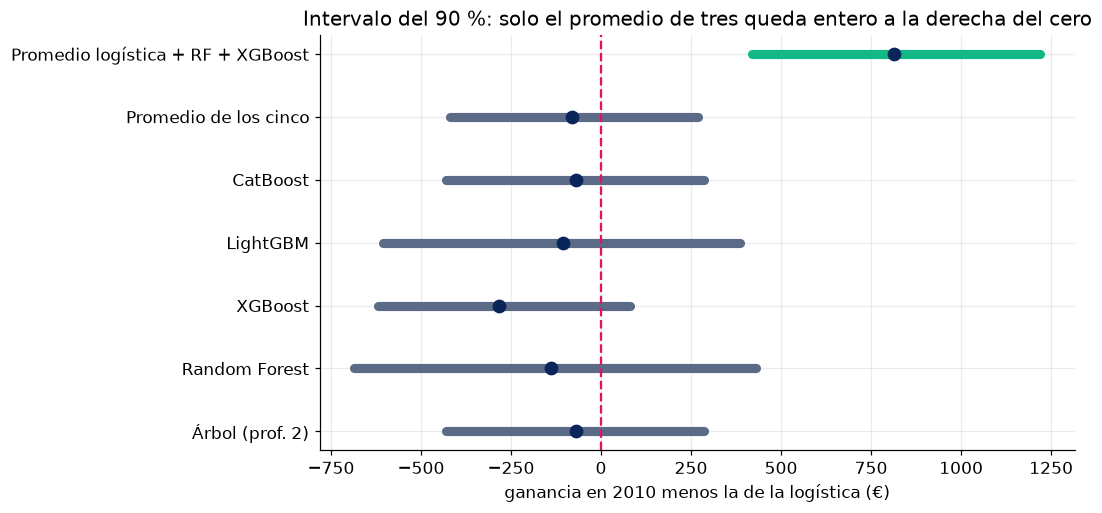

In [29]:
# ── DEMOSTRACIÓN 4.3 ─────────────────────────────────────────────────────
if p05 is not None:
    nombres = ["Árbol (prof. 2)", "Random Forest", "XGBoost", "LightGBM", "CatBoost", "Promedio de los cinco", "Promedio logística + RF + XGBoost"]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for k, n in enumerate(nombres):
        d = diferencias_bootstrap(n)
        lo, hi = np.percentile(d, [5, 95])
        color = GREEN if lo > 0 else GRAY
        ax.plot([lo, hi], [k, k], color=color, lw=6, solid_capstyle="round")
        ax.plot(d.mean(), k, "o", color=NAVY, ms=8)
        print(f"{n:>34}: media {euros(d.mean()):>6} · 90 % [{euros(lo)}, {euros(hi)}] · gana en el {(d > 0).mean():.0%}")
    ax.axvline(0, color=MAG, ls="--", lw=1.5)
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres)
    ax.set_xlabel("ganancia en 2010 menos la de la logística (€)")
    ax.set_title("Intervalo del 90 %: solo el promedio de tres queda entero a la derecha del cero")
    plt.tight_layout(); plt.show()

| Contra la logística | Diferencia media | Intervalo del 90 % | Gana en |
|---|---|---|---|
| Árbol (prof. 2) | −€70 | [−€430, €285] | 37 % |
| Random Forest | −€138 | [−€685, €430] | 33 % |
| XGBoost | −€292 | [−€645, €70] | 9 % |
| LightGBM | −€107 | [−€605, €385] | 36 % |
| CatBoost | −€70 | [−€430, €285] | 37 % |
| Promedio de los cinco | −€148 | [−€490, €210] | 22 % |
| Promedio logística + RF + XGBoost | €302 | [€105, €500] | 99 % |

- **Ningún modelo solo se distingue de la logística:** los cinco intervalos cruzan el cero. XGBoost incluso pierde en el 91 % de las muestras.
- **El promedio de tres gana en el 99 % de las muestras**, por entre €105 y €500.
- **El promedio de cinco gana solo en el 22 %.** Agregar LightGBM y CatBoost lo empeoró.

### ¿Entonces el promedio de tres funciona, o tuvimos suerte?

Las dos cosas pueden ser ciertas, y conviene separarlas:

1. **Por qué puede funcionar.** La logística, el bosque y XGBoost se equivocan en clientes distintos, y al promediar esos
   errores se cancelan en parte. Es la idea del Random Forest con modelos de familias diferentes. LightGBM y CatBoost, en
   cambio, se parecen mucho al árbol chico y a XGBoost: suman votos que ya estaban.
2. **Por qué hay que desconfiar.** Probamos dos combinaciones y miramos cuál ganaba **en 2010**. El bootstrap mide el ruido
   de la muestra de 2010, **no el de nuestras decisiones**: si probamos suficientes combinaciones, alguna va a ganar por azar.
   En validación, que es donde había que elegir, el de tres ganaba €6 085 y el de cinco €6 055: €30 de diferencia no es señal.

> La regla sana: **la combinación se elige en validación y se anuncia antes de mirar el OOT**. El OOT se mira una vez.
> Con lo que tenemos, la logística sigue como modelo oficial y el promedio de tres queda como retador, para medirlo mes a mes.
> En la Clase 13, el *stacking* elige los pesos de cada modelo con validación cruzada temporal, que es la versión ordenada de esta idea.

### ¿Por qué en la Clase 4 los árboles arrasaron y hoy no?

| | California Housing (Clase 4) | Banco (Clases 6 a 8) |
|---|---|---|
| La señal | geográfica: costas, bahías, barrios. Curvas e interacciones | casi toda en tres preguntas: contactado antes, canal, resultado previo |
| Regresión lineal o logística | R² 0.651 | AUC 0.704 |
| El mejor modelo de árboles | **R² 0.841** (XGBoost) | AUC 0.704 (XGBoost) |
| Árboles que eligió la parada temprana | 981 | 4 a 11 (LightGBM, CatBoost, XGBoost) |

> Un modelo más complejo solo gana si hay **estructura que el simple no ve**. En riesgos, eso se usa a propósito: la logística
> queda como **modelo oficial** y el de árboles como **retador** (*challenger*). Si el retador gana por mucho, hay una señal escondida
> que vale la pena buscar; si empata, como hoy, la logística se queda, porque se puede explicar variable por variable.

---
# Bloque 5 · Cierre del Módulo 2: preguntas tipo examen  ·  12 min

### El módulo en una tabla

| Clase | La pregunta | La respuesta que nos llevamos |
|---|---|---|
| 6 | ¿Cómo se arma y se mide un modelo de propensión? | Pegar fuentes con control de filas, sacar las fugas (`duracion_seg`), **cortar por tiempo**, logística, AUC, KS y Gini |
| 7 | ¿Dónde se corta la lista? | Árboles, KNN y SVC empatan; **el umbral elegido por ganancia vale más que el modelo** |
| 8 | ¿Muchos árboles le ganan a la logística? | No con estas variables, ni el bosque ni los tres boostings. Validar con el futuro (el OOB no alcanza), medir importancias en datos nuevos y **probar si una diferencia es real** |

### Preguntas tipo examen

Respóndelas primero sin mirar el notebook. Las que piden una cuenta se hacen con calculadora. Las que no alcancen en clase quedan de tarea.

**1.** Un modelo de propensión tiene **92.7 % de exactitud** en el entrenamiento. ¿Es un buen modelo?

> **Respuesta.** No se puede saber, y probablemente no. En el entrenamiento contrata el 7.3 %: **no llamar a nadie** ya da 92.7 % de exactitud. Con clases desbalanceadas se mira el AUC, el KS, el PR-AUC o, mejor, la ganancia.

**2.** ¿Por qué sacamos `duracion_seg` del modelo, si es la variable que más predice?

> **Respuesta.** Porque se conoce **al colgar**: cuando hay que decidir a quién llamar, todavía no existe. Es una fuga (*leakage*): el modelo se ve muy bien en la prueba y no se puede usar en la realidad.

**3.** Un nodo tiene 120 clientes y contratan 30. Calcula su **Gini** y su **entropía**.

> **Respuesta.** p = 30/120 = 0.25. Gini = 1 − 0.25² − 0.75² = 1 − 0.0625 − 0.5625 = **0.375**. Entropía = −(0.25·log₂0.25 + 0.75·log₂0.75) = 0.25·2 + 0.75·0.415 = **0.811**.

**4.** La logística tiene un AUC de 0.704 en 2010. ¿Cuál es su **Gini de riesgo**?

> **Respuesta.** Gini = 2·AUC − 1 = 2·0.704 − 1 = **0.408**. Ojo: no es el Gini de impureza de los árboles; comparten el nombre y nada más.

**5.** Cada llamada cuesta €20 y cada venta deja €50. ¿Cuál es el **umbral teórico**? ¿Por qué no lo usamos tal cual?

> **Respuesta.** Conviene llamar si p·50 > 20, o sea **p > 20/50 = 0.40**. Solo vale si las probabilidades están calibradas, y las nuestras no: el modelo aprendió con un 7 % de éxito y en 2010 la tasa fue 52 %. Por eso elegimos el umbral que más gana en validación.

**6.** ¿Qué cambia y qué no cuando usas `class_weight="balanced"` o `scale_pos_weight`?

> **Respuesta.** Cambian **las probabilidades** (suben mucho, y con el 0.5 se llama a muchos más). **No cambia el orden**: el AUC queda casi igual y la correlación de Spearman entre los scores es de 0.94 a 0.98. Es mover el umbral por otra vía, y de paso descalibra.

**7.** El PR-AUC de la logística sube de 0.540 en validación a 0.703 en 2010. ¿Mejoró el modelo?

> **Respuesta.** No. La línea base del PR-AUC es la tasa de positivos, y subió de 0.398 a 0.521. El **lift** (PR-AUC entre la línea base) queda igual: 1.36 contra 1.35. Un PR-AUC solo se lee junto a su línea base.

**8.** Un Random Forest con `min_samples_leaf=400` tiene AUC OOB 0.635 y AUC en validación 0.553. ¿Qué pasó, y cuál de los dos números le crees?

> **Respuesta.** Las hojas de 400 no pueden aislar a los 342 clientes ya contactados del entrenamiento. Dentro de 2008–2009 eran el 0.9 %, así que el OOB, que mezcla esos mismos meses, casi no lo nota. En la validación son el 20 % y el modelo se hunde. **Le creo a la validación**, porque se parece al futuro donde se va a usar el modelo.

**9.** XGBoost gana €14 170 en 2010 y la logística €14 455. ¿Cuál pondrías en producción?

> **Respuesta.** La **logística**: el bootstrap muestra que la diferencia no es consistente, y la logística se explica variable por variable. XGBoost queda como modelo retador. El promedio de tres ganó en el 99 % de las muestras bootstrap, pero el de cinco no: la ventaja depende de qué combinación se elija, y la elegimos mirando 2010. También queda como retador.

**10.** ¿En qué se diferencian XGBoost, LightGBM y CatBoost?

> **Respuesta.** Los tres son boosting de árboles. XGBoost hace crecer cada árbol por niveles y necesita las categóricas codificadas. LightGBM lo hace por hojas, agrupa las numéricas en histogramas y acepta categóricas nativas: es el más rápido con muchas filas. CatBoost usa árboles simétricos y convierte cada categoría en una tasa calculada solo con los clientes anteriores, para no tener fuga: no hay que codificar nada, pero es más lento.

### Ejercicio 5.1 — Dos cuentas para calentar

Comprueba con código dos de las respuestas de arriba: el Gini y la entropía del nodo de la pregunta 3, y el Gini de
riesgo de la logística en 2010.

In [30]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
p_nodo = 30 / 120
gini_nodo = 1 - p_nodo**2 - (1 - p_nodo)**2
entropia_nodo = -(p_nodo * np.log2(p_nodo) + (1 - p_nodo) * np.log2(1 - p_nodo))
gini_riesgo = 2 * roc_auc_score(y_oot, p_oot) - 1
print(f"Gini del nodo {gini_nodo:.3f} · entropía {entropia_nodo:.3f} · Gini de riesgo de la logística en 2010 {gini_riesgo:.3f}")

Gini del nodo 0.375 · entropía 0.811 · Gini de riesgo de la logística en 2010 0.408


In [31]:
# ── VERIFICACIÓN 5.1 ─────────────────────────────────────────────────────
r = [check("Gini del nodo", gini_nodo, 0.3750),
     check("entropía del nodo", entropia_nodo, 0.8113),
     check("Gini de riesgo de la logística en 2010", gini_riesgo, 0.4084)]
print()
print("Bloque 5 COMPLETO" if all(r) else "Revisa 5.1")

[OK] Gini del nodo
     tu resultado: 0.3750   |   esperado: 0.3750
[OK] entropía del nodo
     tu resultado: 0.8113   |   esperado: 0.8113
[OK] Gini de riesgo de la logística en 2010
     tu resultado: 0.4084   |   esperado: 0.4084

Bloque 5 COMPLETO


---
# Cierre

### Los números del día

| | AUC OOT | Ganancia 2010 | ¿Le gana a la logística? |
|---|---|---|---|
| Regresión logística (Clase 6) | 0.704 | €14 455 | es la marca |
| Random Forest, hojas de 200 | 0.698 | €14 315 | no: el intervalo cruza el cero |
| XGBoost, 11 árboles de 2 niveles | 0.704 | €14 170 | no: pierde en el 91 % de las muestras |
| LightGBM, 4 árboles de 8 hojas | 0.695 | €14 355 | no: el intervalo cruza el cero |
| CatBoost, 5 árboles de profundidad 4 | 0.693 | €14 395 | no: arma la misma lista que el árbol de 2 niveles |
| **Promedio de los tres** | 0.703 | **€14 760** | **por poco: +€305, en el 99 % de las muestras** |
| Promedio de los cinco | 0.702 | €14 320 | no: gana solo en el 22 % |

### Checklist de salida

- [ ] Sé que en clasificación el bosque promedia las tasas de las hojas, y que con hojas puras es una votación.
- [ ] Ajusto `min_samples_leaf`: el Random Forest por defecto memoriza.
- [ ] Sé que el OOB mezcla meses como un split aleatorio, y que no reemplaza a la validación temporal.
- [ ] Distingo la importancia por impureza (qué usó para aprender) de la de permutación (qué le sirve para predecir).
- [ ] Uso la parada temprana en XGBoost, LightGBM y CatBoost, y leo cuántos árboles eligió como una medida de cuánta señal hay.
- [ ] Sé cuándo conviene cada boosting: LightGBM con muchas filas, CatBoost con muchas categóricas.
- [ ] Sé que `scale_pos_weight`, igual que `class_weight`, mueve las probabilidades y no el orden.
- [ ] Antes de declarar un ganador, pruebo con bootstrap si la diferencia es consistente, y elijo combinaciones en validación, no en el OOT.

### Lo que sigue

- **Parcial de los Módulos 1 y 2:** fecha por confirmar. Entra todo lo de las Clases 1 a 8; el Bloque 5 de hoy es un buen punto de partida.
- **LightGBM y CatBoost ya los vimos hoy:** la Clase 13 queda para bagging y *stacking*, y eso libera tiempo en el calendario.
- **Clase 9 · Clustering:** K-Means sobre el maestro de clientes del banco. Dejamos de predecir quién contrata y empezamos a preguntar qué tipos de clientes hay.